<h1 style="color: #FFD700; text-align: center;">🎨 Classification Fashion MNIST</h1>
<h3 style="color: #00FFFF; text-align: center;">Classer les images de vêtements en 10 catégories</h3>

<hr style="border: 2px solid #FFD700;">

<p style="font-size:16px; color:#FFFFFF;">
🧵 <b>Description du projet :</b><br>
Ce projet consiste à classifier des images de vêtements à partir de la base <b>Fashion MNIST</b>.  
Nous utiliserons <b>Python, TensorFlow / Keras, et NumPy</b> pour construire un modèle simple et efficace.
</p>

<p style="font-size:16px; color:#ADFF2F;">
✨ <b>Objectifs :</b><br>
1. Explorer les données et analyser la distribution des classes<br>
2. Construire un réseau de neurones pour la classification<br>
3. Évaluer les performances avec l’accuracy et la matrice de confusion<br>
4. Améliorer le modèle et visualiser les prédictions correctes et incorrectes
</p>


In [ ]:
# import tensorflow as tf
# import matplotlib.pyplot as plt

# # 1. Chargement direct depuis Keras
# fashion_mnist = tf.keras.datasets.fashion_mnist
# (X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# # 2. Vérification des dimensions
# print(f"Images d'entraînement : {X_train.shape}")  # Doit afficher (60000, 28, 28)
# print(f"Images de test : {X_test.shape}")          # Doit afficher (10000, 28, 28)

# # 3. Liste des noms de classes (pour l'affichage)
# class_names = ["T-shirt/top", "Pantalon", "Pull", "Robe", "Manteau",
#                "Sandale", "Chemise", "Basket", "Sac", "Bottine"]

# # 4. Afficher la première image pour vérifier
# plt.imshow(X_train[0], cmap="binary")
# plt.title(class_names[y_train[0]])
# plt.axis('off')
# plt.show()

In [2]:
import urllib.request
import os
import gzip
import numpy as np

os.makedirs("data/fashion", exist_ok=True)

urls = {
    "train_images": "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/train-images-idx3-ubyte.gz",
    "train_labels": "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/train-labels-idx1-ubyte.gz",
    "test_images":  "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/t10k-images-idx3-ubyte.gz",
    "test_labels":  "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/t10k-labels-idx1-ubyte.gz"
}

for name, url in urls.items():
    path = f"data/fashion/{url.split('/')[-1]}"
    if not os.path.exists(path):
        print(f"Téléchargement de {url}...")
        urllib.request.urlretrieve(url, path)
    else:
        print(f"{path} existe déjà.")

def load_mnist_images(filename):
    with gzip.open(filename, 'rb') as f:
        f.read(16)  
        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.reshape(-1, 28, 28)

def load_mnist_labels(filename):
    with gzip.open(filename, 'rb') as f:
        f.read(8)  
        return np.frombuffer(f.read(), dtype=np.uint8)
X_train = load_mnist_images("data/fashion/train-images-idx3-ubyte.gz")
y_train = load_mnist_labels("data/fashion/train-labels-idx1-ubyte.gz")
X_test  = load_mnist_images("data/fashion/t10k-images-idx3-ubyte.gz")
y_test  = load_mnist_labels("data/fashion/t10k-labels-idx1-ubyte.gz")

data/fashion/train-images-idx3-ubyte.gz existe déjà.
data/fashion/train-labels-idx1-ubyte.gz existe déjà.
data/fashion/t10k-images-idx3-ubyte.gz existe déjà.
data/fashion/t10k-labels-idx1-ubyte.gz existe déjà.


In [3]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]


In [4]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (60000, 28, 28)
y_train shape: (60000,)


Conversion des données de array à dataFrame

In [5]:
import pandas as pd

# Flatten Photos
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat  = X_test.reshape(X_test.shape[0], -1)

# Convertir en DataFrame
X_train_df = pd.DataFrame(X_train_flat)
#X_test_df  = pd.DataFrame(X_test_flat)

#Étiquettes
y_train_sr = pd.Series(y_train, name="label")
# y_test_sr  = pd.Series(y_test, name="label")

train_df = pd.concat([X_train_df, y_train_sr], axis=1)

In [6]:
train_df.head()

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,label
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,9
1,0,0,0,0,0,1,0,0,0,0,...,114,130,76,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,22,...,0,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,33,96,...,0,0,0,0,0,0,0,0,0,3
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


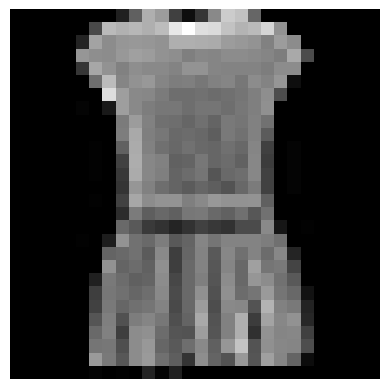

In [7]:
import matplotlib.pyplot as plt
def plot_digit(image_data):
    image = image_data.reshape(28, 28)
    plt.imshow(image, cmap="gray")
    plt.axis("off")
some_digit = X_train_flat[3]
plot_digit(some_digit)
plt.show()

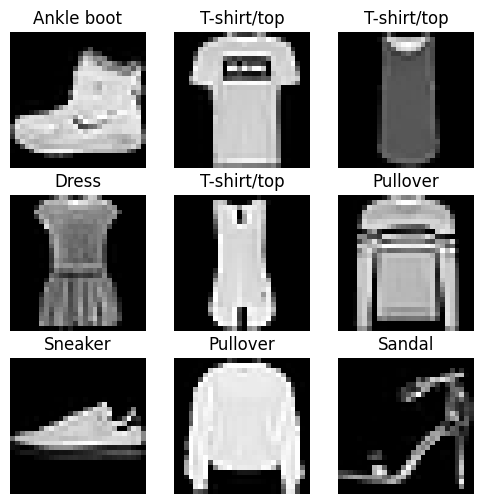

In [8]:
plt.figure(figsize=(6,6))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(X_train[i], cmap="gray", interpolation="nearest")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.show()


### Training a Binary Classifier

on travaille sur le binaire "Est-ce une Dress (3) ?"

In [9]:
y_train_dress = (y_train == 3)
y_test_dress = (y_test == 3)

In [10]:
y_train_dress

array([False, False, False, ...,  True, False, False], shape=(60000,))

# stochastic gradient descent (SGD, or stochastic GD) classifier

SGDClassifier est un classificateur qui apprend en utilisant la descente de gradient stochastique.
Concrètement :

* Le système analyse un exemple (image, suite de chiffres, etc.).

* Il commet une erreur ou trouve la bonne réponse.

* Il s’ajuste légèrement.

* Il passe à l’exemple suivant.

* Et ainsi de suite, petit à petit.

Pourquoi est-ce important ?

Parce que Fashion-MNIST contient 60 000 images.

Télécharger l’ensemble de ces images, calculer l’erreur globale, puis mettre à jour le système… serait long et fastidieux.

#### Test Rapide SANS Scaling

In [11]:
print(X_train.shape)
print(y_train_dress.shape)

(60000, 28, 28)
(60000,)


In [12]:
X_test_flat

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(10000, 784), dtype=uint8)

In [13]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(max_iter=5000, tol=1e-3,random_state=42)
#X_train est de forme (60000, 28, 28) mais  X_train_flat a la forme (60000, 784)
sgd_clf.fit(X_train_flat, y_train_dress)

,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,5000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


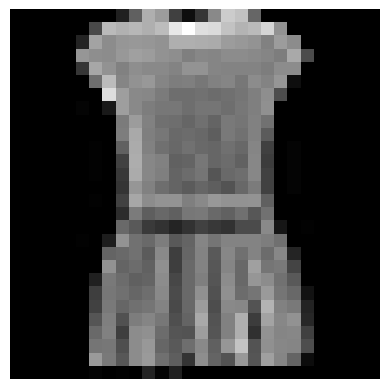

In [14]:
plot_digit(X_train_flat[3]) #=> is a dress

In [15]:
y_train[3]

np.uint8(3)

In [16]:
prediction_1 = sgd_clf.predict([X_train_flat[3]])
print(f"Est-ce une robe ?  => {prediction_1}")


Est-ce une robe ?  => [False]


Bien que l'exemple 3 soit effectivement la photo d'une robe, le mannequin n'a pas reconnu la robe.

In [17]:
y_score = sgd_clf.decision_function([X_train_flat[3]])
print(f"Score: {y_score}")

Score: [-272.75970431]


Le nombre est souvent négatif, ce qui signifie que le modèle « croit fermement » qu'il ne s'agit pas d'une robe.

le model calcule un score = w.x + b
* Score > 0 → Le modèle tend vers la catégorie positive.

* Score < 0 → Le modèle tend vers la catégorie négative.

### Performance Measures

Measuring Accuracy Using Cross-Validation

In [18]:
from sklearn.model_selection import cross_val_score
import time

print("--- Entraînement SANS Scaling ---")
start_time = time.time()
# On lance une validation croisée rapide
scores = cross_val_score(sgd_clf, X_train_flat, y_train_dress, cv=3, scoring="accuracy")
print(f"Temps : {time.time() - start_time:.2f} secondes")
print(f"Exactitude : {scores}")
print(f"Exactitude moyenne : {scores.mean():.4f}")

--- Entraînement SANS Scaling ---
Temps : 63.72 secondes
Exactitude : [0.94835 0.9628  0.9597 ]
Exactitude moyenne : 0.9569


IMPLEMENTING CROSS-VALIDATION

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

skfolds = StratifiedKFold(n_splits=3)
for train_index, test_index in skfolds.split(X_train_flat,y_train_dress):
    clone_clf = clone(sgd_clf) # Crée un nouveau model avec les mêmes paramètres
    X_train_folds = X_train_flat[train_index] #Création de données d'entraînement
    y_train_folds = y_train_dress[train_index] #Création de données de test
    X_test_fold = X_train_flat[test_index]
    y_test_fold = y_train_dress[test_index]
    clone_clf.fit(X_train_folds, y_train_folds)
    y_pred = clone_clf.predict(X_test_fold)
    n_correct = sum(y_pred == y_test_fold)

print(n_correct / len(y_pred))

0.9597


La précision est également élevée, même si les résultats sont médiocres. Par conséquent, la précision ne nous renseigne pas toujours sur la qualité du modèle… 

« La précision peut être trompeuse. »

In [20]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier()
dummy_clf.fit(X_train_flat,y_train_dress)

,strategy,'prior'
,random_state,None
,constant,None


In [39]:
print(any(dummy_clf.predict(X_train_flat)))

False


La fonction `any()` vérifie si les prédictions contiennent au moins `True`, c'est-à-dire si un 3  est identifié.

Dans cet notre cas, le résultat est `False` : aucun 3 n'a été identifié.

In [22]:
print("--- Entraînement Avec DummyClassifier ---")
start_time = time.time()
# On lance une validation croisée rapide
scores = cross_val_score(dummy_clf, X_train_flat, y_train_dress, cv=3, scoring="accuracy")
print(f"Temps : {time.time() - start_time:.2f} secondes")
print(f"Exactitude : {scores}")
print(f"Exactitude moyenne : {scores.mean():.4f}")

--- Entraînement Avec DummyClassifier ---
Temps : 0.10 secondes
Exactitude : [0.9 0.9 0.9]
Exactitude moyenne : 0.9000


>C'est une fausse précision.

Le classificateur DummyClassifier n'apprend pas du tout à partir des images.

Par défaut, il se contente de :

* Analyser la distribution des classes dans y_train

* Puis prédire systématiquement la classe la plus fréquente

> Précision = Nombre de prédictions correctes ÷ Nombre total

S'il indique systématiquement « pas une robe » :

* Il aura raison dans 90 % des cas

* Il se trompera pour toutes les robes

## Confusion Matrices

La matrice de confusion sert à compter le nombre de fois où
les instances de la classe A sont classées comme appartenant à la classe B, pour toutes les paires A/B.

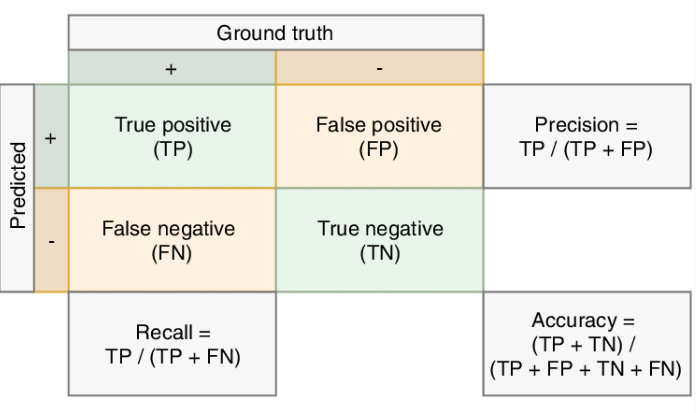

Pour calculer la matrice de confusion, nous avons d'abord besoin d'un ensemble de prédictions afin de pouvoir les comparer aux cibles réelles.

In [25]:
from sklearn.model_selection import cross_val_predict
y_train_pred = cross_val_predict(sgd_clf, X_train_flat, y_train_dress,
cv=3)

* cross_val_predict() :  performs k-fold cross-validation, but instead of
returning the evaluation scores, it returns the predictions made on each test
fold.

get the confusion matrix

In [28]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_train_dress, y_train_pred)
print(f"matrice de confusion :")
cm


matrice de confusion :


array([[52927,  1073],
       [ 1510,  4490]])

[[TN, FP],
 [FN, TP]]

* 52927 — True Negatives (TN)

✔ Images ne provenant pas du public cible, et le mannequin a indiqué « non ».

* 1073 — Faux positifs (FP)

❌ Photos qui ne font pas partie de la catégorie, mais que le modèle a déclaré « qu’elles font partie de la catégorie ».

* 1510 — Faux négatifs (FN)

❌ Les images appartiennent bien à la catégorie, mais le modèle n'a pas réussi à les détecter.

Il s'agit souvent de l'erreur la plus grave.

* 4490 — Vrais positifs (VP)

✔ Images de la catégorie pour lesquelles le modèle a été détecté avec succès.

>Ce modèle est conservateur :

Il a tendance à dire « non » fréquemment.

Il excelle à rejeter ceux qui ne correspondent pas au profil type.

Mais il passe à côté de nombreuses situations concrètes(1510)

**A perfect classifier would only have true positives and true negatives, so its confusion matrix would have nonzero values only on its main diagonal (top left to bottom right)**

### Precision and Recall

In [29]:
from sklearn.metrics import precision_score, recall_score
precision = precision_score(y_train_dress,y_train_pred)
recall = recall_score(y_train_dress,y_train_pred)
print(f"precision score : {precision}")
print(f"recall score : {recall}")

precision score : 0.807118461261909
recall score : 0.7483333333333333


precision score : Quand il dit « oui », est-il sincère ?
Precision = TP / (TP + FP) = 80.71% => Il se trompe environ une fois sur 5.

recall score : Parmi tous les cas réels, combien ont été découverts ?
Recall = TP / (TP + FN) = 74.8% => Le modèle ne représente qu'environ un quart des robes réelles.


### F1 score

In [30]:
from sklearn.metrics import f1_score
f1 = f1_score(y_train_dress,y_train_pred)
print(f"f1 score : {f1}")


f1 score : 0.7766150652944738


Le modèle n'est pas mal ✔️

Mais il n'est pas parfaitement équilibré.

-----
F1 est la moyenne harmonique entre la précision et le rappel, et non la moyenne simple.

La moyenne harmonique pénalise tout déséquilibre.

Conclusion :

* Si la précision est élevée et le rappel faible → F1 diminue.

* Si le rappel est élevé et la précision faible → F1 diminue.

* Si la précision et le rappel sont équilibrés → F1 augmente. (Elle ne veut pas prendre parti.)

Autrement dit, F1 signifie :

* Ne me trompez pas avec un seul chiffre flatteur ; je veux les deux.
> F1 ne vous dit pas ce qui est le mieux : la précision ou le rappel.
Elle vous indique seulement si la relation entre les deux est saine ou non.

the decision scores

In [35]:
y_scores = sgd_clf.decision_function([X_train_flat[3]])

In [ ]:
threshold = 0
y_some_clothes_pred = (y_scores > threshold) # =>the same result as the predict() method


In [ ]:
print(f"score = {y_scores}")
print(f"Pour threshold =0 : est-ce positif ? est-ce une robe ? => {y_some_clothes_pred}")

score = [-272.75970431]
est-ce positif ? est-ce une robe ? => [False]


La valeur est négative.

Et loin d'être nulle.

=> C'est un refus catégorique. Ce n'est pas une robe.

In [39]:
threshold = 3000
y_some_clothes_pred = (y_scores > threshold)

In [40]:
print(f"Pour threshold =0 : est-ce positif ? est-ce une robe ? => {y_some_clothes_pred}")

Pour threshold =0 : est-ce positif ? est-ce une robe ? => [False]


aussi ,le classificateur ne le détecte pas lorsque le seuil est augmenté à 3 000.

Comment choisir le seuil à utiliser ?

In [ ]:
#Commencez par utiliser la fonction cross_val_predict() 
# pour obtenir les scores de toutes les instances de l’ensemble d’entraînement
y_scores = cross_val_predict(sgd_clf,X_train_flat,y_train_dress,cv=3,method="decision_function")

In [42]:
#fonction precision_recall_curve() pour calculer la précision
#  et le rappel pour tous les seuils possibles (la fonction ajoute
#  une dernière précision de 0 et un dernier rappel de 1, correspondant
#  à un seuil infini)

from sklearn.metrics import precision_recall_curve
 
precisions , recalls , thresholds = precision_recall_curve(y_train_dress,y_scores)

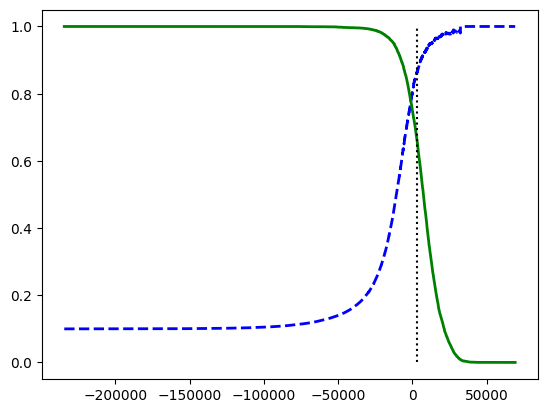

In [43]:
plt.plot(thresholds, precisions[:-1], "b--", label="Precision",
linewidth=2)
plt.plot(thresholds, recalls[:-1], "g-", label="Recall",
linewidth=2)
plt.vlines(threshold, 0, 1.0, "k", "dotted", label="threshold")
[...] # beautify the figure: add grid, legend, axis, labels, and circles
plt.show()

#### Application du Scaling

In [72]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_flat.astype(np.float64))
X_test_scaled = scaler.transform(X_test_flat.astype(np.float64))
print("Données mises à l'échelle. Moyenne globale proche de 0.")


Données mises à l'échelle. Moyenne globale proche de 0.


In [73]:
sgd_clf.fit(X_train_scaled, y_train_dress)
some_item_scaled = scaler.transform([X_train_flat[3].astype(np.float64)])
prediction = sgd_clf.predict(some_item_scaled)

In [75]:
print(f"Est-ce une dress? => {prediction}")

Est-ce une dress? => [ True]


In [ ]:

print("\n--- Entraînement AVEC Scaling ---")
start_time = time.time()
scores_scaled = cross_val_score(sgd_clf, X_train_scaled, y_train_dress, cv=3, scoring="accuracy")
print(f"Temps : {time.time() - start_time:.2f} secondes")
print(f"Exactitude : {scores}")
print(f"Exactitude moyenne : {scores_scaled.mean():.4f}")